other workflows in Langgraph 

## Parallelization in LangGraph

"Parallelization is a workflow pattern in which multiple independent tasks are executed simultaneously, and their results are combined for further processing."

Suppose user bolta hai:

"Analyze this product and tell me about its market, competitors and technical features."

Tumhe 3 tasks perform karne hain:
- Market research
- Competitor analysis
- Technical analysis
Kya inhe ek-ek karke execute karna zaroori hai? Nahi! Ye independent tasks hain, toh parallel execute kar sakte hain.


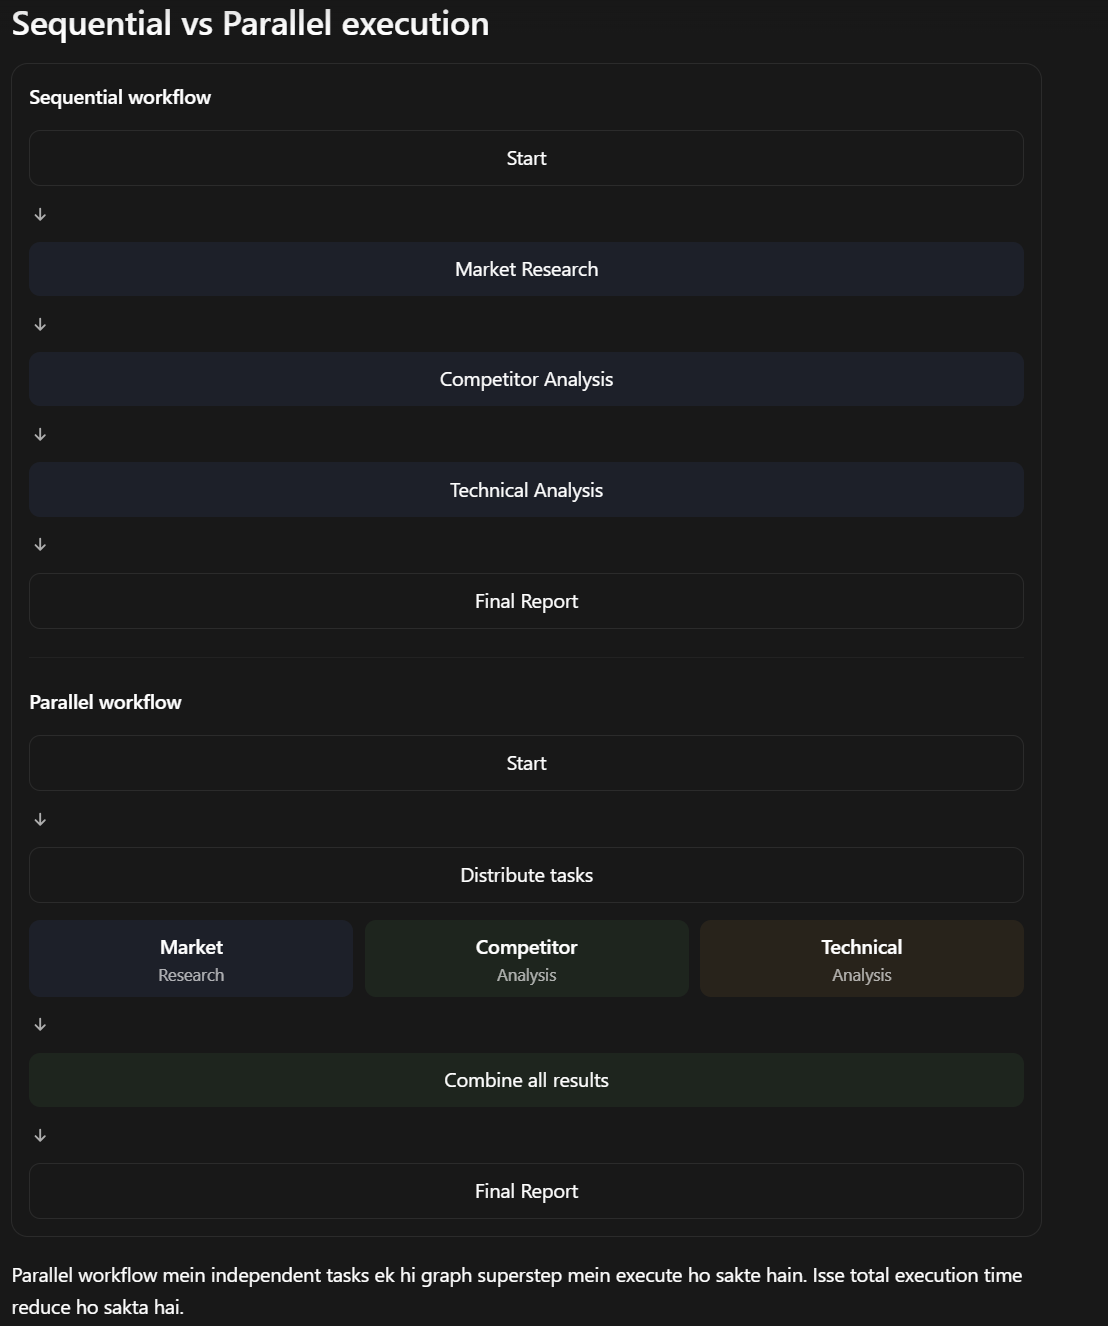

Practical implementation
Ab ek simple example banate hain.

Suppose user ek topic deta hai: Artificial Intelligence.

Humein 3 different analyses generate karne hain:
- Summary
- Advantages
- Disadvantages


In [7]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Did you know? India is home to the world’s only **floating post office**! Located on Dal Lake in Srinagar, the “Bharat Post” service operates from a boat that delivers mail, parcels, and even offers a small souvenir shop—all while gently bobbing on the water. It’s a unique blend of tradition and ingenuity that’s become a popular tourist attraction and a quirky piece of India’s postal history. 🌊📬


In [8]:
# Define State
from typing import TypedDict

class GraphState(TypedDict):
    topic: str
    summary: str
    advantages: str
    disadvantages: str

In [9]:
# Create 3 Nodes

def summary_node(state: GraphState):

    response = llm.invoke(
        f"Give a short summary of {state['topic']}"
    )

    return {
        "summary": response.content
    }


def advantages_node(state: GraphState):

    response = llm.invoke(
        f"Explain the advantages of {state['topic']}"
    )

    return {
        "advantages": response.content
    }


def disadvantages_node(state: GraphState):

    response = llm.invoke(
        f"Explain the disadvantages of {state['topic']}"
    )

    return {
        "disadvantages": response.content
    }

In [10]:
# create graph 
from langgraph.graph import StateGraph, START, END

builder = StateGraph(GraphState)

# Add nodes
builder.add_node("summary", summary_node)
builder.add_node("advantages", advantages_node)
builder.add_node("disadvantages", disadvantages_node)

# Parallel execution
builder.add_edge(START, "summary")
builder.add_edge(START, "advantages")
builder.add_edge(START, "disadvantages")

# Join all branches
builder.add_edge(
    ["summary", "advantages", "disadvantages"],
    END
)

graph = builder.compile()

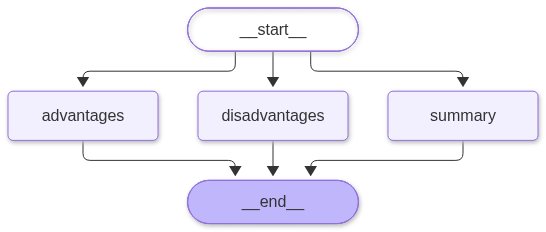

In [11]:
from IPython.display import display, Markdown, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
#Invoke 
result = graph.invoke({
    "topic": "Artificial Intelligence",
    "summary": "",
    "advantages": "",
    "disadvantages": ""
})

print("SUMMARY:")
print(result["summary"])

print("\nADVANTAGES:")
print(result["advantages"])

print("\nDISADVANTAGES:")
print(result["disadvantages"])

SUMMARY:
Artificial Intelligence (AI) is a branch of computer science focused on creating systems that can perform tasks typically requiring human intelligence. These tasks include learning from data (machine learning), recognizing patterns (computer vision, speech recognition), reasoning and problem‑solving, understanding natural language, and making decisions. AI techniques range from rule‑based expert systems to deep neural networks that can process vast amounts of information. The field aims to develop algorithms and models that enable machines to adapt, improve, and operate autonomously across a wide variety of applications—from virtual assistants and recommendation engines to autonomous vehicles and medical diagnostics.

ADVANTAGES:
**Artificial Intelligence (AI) brings a wide range of benefits across many sectors and aspects of daily life. Below is a structured overview of the most significant advantages, grouped by theme and illustrated with concrete examples.**  

---

## 1. E

## Important concept: Reducers in parallel execution
Suppose multiple nodes same State key update karne ki koshish karein.

class GraphState(TypedDict):
    results: list

Agar teen parallel nodes results ko independently update karenge, toh default State update behavior mein conflict aa sakta hai.

Isliye reducer use karte hain.

from typing import Annotated
import operator

class GraphState(TypedDict):
    results: Annotated[list, operator.add]



Ab parallel nodes return kar sakte hain:
Node 1 return {"results": ["Summary"]}
Node 2 return {"results": ["Advantages"]}
Node 3 return {"results": ["Disadvantages"]}


Reducer operator.add lists ko combine karega.

# Workflow pattern 2 : Routing
Routing is a workflow pattern where an input is analyzed and dynamically directed to the most appropriate node based on predefined conditions or an LLM's decision."

Simple example:

Suppose tum ek AI learning assistant bana rahe ho.

User teen types ke questions pooch sakta hai:
- Python question → Python Expert Node
- Java question → Java Expert Node
- Other question → General Expert Node
Hum nahi chahte ki har question par teeno nodes execute hon.

Sirf relevant node execute hona chahiye.

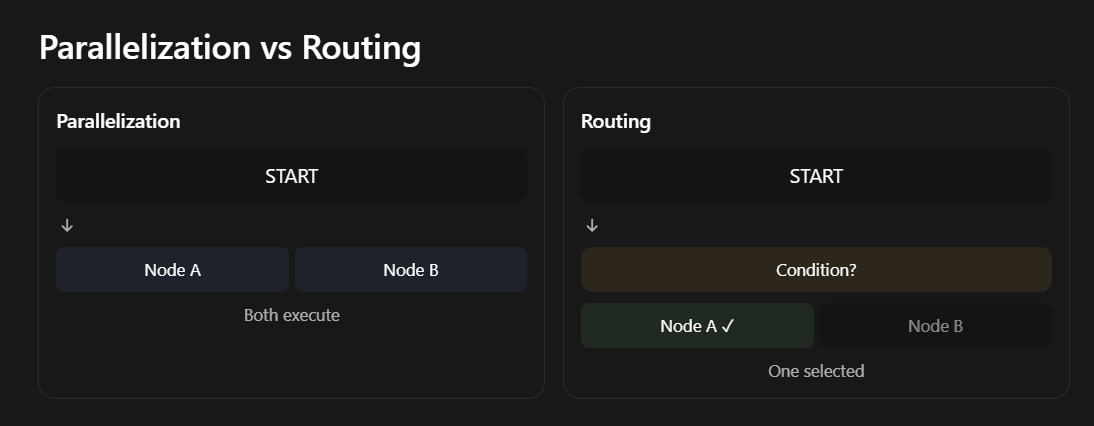

In [13]:
# Define State

from typing import TypedDict

class GraphState(TypedDict):
    question: str
    category: str
    answer: str

In [16]:
# Create Nodes:
def classify_node(state: GraphState):
    question = state["question"].lower()

    if "python" in question:
        category = "python"
    elif "java" in question:
        category = "java"
    else:
        category = "general"

    return {"category": category}


def python_node(state: GraphState):
    response = llm.invoke(
        f"Answer this Python question simply: {state['question']}"
    )
    return {"answer": response.content}


def java_node(state: GraphState):
    response = llm.invoke(
        f"Answer this Java question simply: {state['question']}"
    )
    return {"answer": response.content}


def general_node(state: GraphState):
    response = llm.invoke(
        f"Answer this question simply: {state['question']}"
    )
    return {"answer": response.content}

## Create Routing Function 
routing function input ko analyze karega aur decide karega ki kaunsa node execute hoga.


In [18]:
def route_question(state: GraphState) -> str:

    if state["category"] == "python":
        return "python"

    elif state["category"] == "java":
        return "java"

    return "general"

In [19]:
# Create Graph
from langgraph.graph import StateGraph, START, END

builder = StateGraph(GraphState)

# Add nodes
builder.add_node("classify", classify_node)
builder.add_node("python_expert", python_node)
builder.add_node("java_expert", java_node)
builder.add_node("general_expert", general_node)

# Starting edge
builder.add_edge(START, "classify")

# Conditional routing
builder.add_conditional_edges(
    "classify",
    route_question,
    {
        "python": "python_expert",
        "java": "java_expert",
        "general": "general_expert"
    }
)

# All expert nodes finish at END
builder.add_edge("python_expert", END)
builder.add_edge("java_expert", END)
builder.add_edge("general_expert", END)

graph = builder.compile()

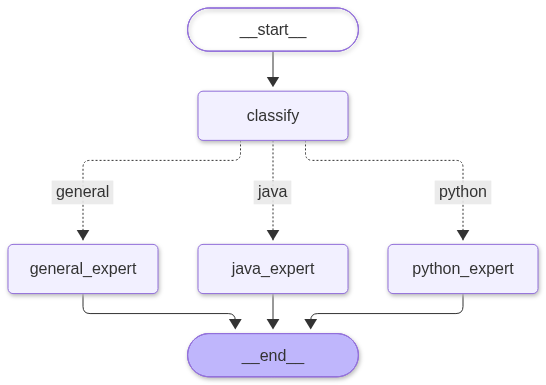

In [20]:
from IPython.display import display, Markdown, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
# Invoke
result = graph.invoke({
    "question": "Explain Python decorators",
    "category": "",
    "answer": ""
})

print("Selected category:", result["category"])
print("Answer:", result["answer"])

Selected category: python
Answer: **Python decorators – a quick, simple rundown**

A *decorator* is a callable (usually a function) that takes another function (or method) as input, adds some extra behavior, and returns a new function that replaces the original one.  
Think of it as “wrapping” a function with extra code, without changing the function’s own source.

---

### How it works in 3 steps

1. **Define a decorator** – a function that receives a function (`func`) and returns a new function (`wrapper`).
2. **Apply it** – using the `@decorator_name` syntax right above the target function, or by calling `decorated = decorator(original)`.
3. **When the target is called**, the wrapper runs first, can do something before/after (or even replace) the original call, then returns the result.

---

### Minimal example

```python
def my_decorator(func):
    def wrapper(*args, **kwargs):
        print("Before the function runs")
        result = func(*args, **kwargs)   # call the original fu

## LLM based Routing 
abhi ham routing function ko LLM ke through implement karenge.
upar wale mein keyword check karke routing kar rahe the, lekin LLM ke through hum complex routing kar sakte hain.

ahan LLM-based routing useful hai.

Hum LLM se structured output lenge:

In [34]:
from typing import TypedDict, Literal
from pydantic import BaseModel

from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END

# Initialize model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [ ]:
class GraphState(TypedDict):
    question: str
    category: str
    answer: str

class RouteDecision(BaseModel):
    category: Literal["python", "java", "general"]

In [29]:
router_llm = llm.with_structured_output(RouteDecision)


def classify_node(state: GraphState):

    decision = router_llm.invoke(
        f"""
        Classify the following question into one of these categories:
        python, java, or general.

        Question: {state['question']}
        """
    )

    return {
        "category": decision.category
    }



In [30]:
#cretae Nodes:

def python_node(state: GraphState):

    response = llm.invoke(
        f"Answer this Python question clearly: {state['question']}"
    )

    return {
        "answer": response.content
    }


def java_node(state: GraphState):

    response = llm.invoke(
        f"Answer this Java question clearly: {state['question']}"
    )

    return {
        "answer": response.content
    }


def general_node(state: GraphState):

    response = llm.invoke(
        f"Answer this question clearly: {state['question']}"
    )

    return {
        "answer": response.content
    }

In [31]:
#routing function
def route_question(state: GraphState):

    return state["category"]

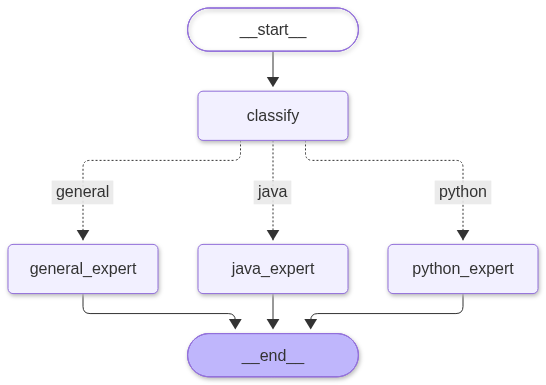

In [32]:
builder = StateGraph(GraphState)

# Add nodes
builder.add_node("classify", classify_node)
builder.add_node("python_expert", python_node)
builder.add_node("java_expert", java_node)
builder.add_node("general_expert", general_node)

# Starting edge
builder.add_edge(START, "classify")

# Conditional routing
builder.add_conditional_edges(
    "classify",
    route_question,
    {
        "python": "python_expert",
        "java": "java_expert",
        "general": "general_expert"
    }
)

# Expert nodes connect to END
builder.add_edge("python_expert", END)
builder.add_edge("java_expert", END)
builder.add_edge("general_expert", END)

# Compile graph
graph = builder.compile()


from IPython.display import display, Image

display(
    Image(graph.get_graph().draw_mermaid_png())
)

In [35]:
result = graph.invoke({
    "question": "Explain Python decorators",
    "category": "",
    "answer": ""
})

print("Selected category:", result["category"])
print("\nAnswer:")
print(result["answer"])

BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is required, but model did not call a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': 'python'}}